<a href="https://colab.research.google.com/github/amrithavi/GENE-PAPER/blob/main/RERUNDNA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q tensorflow pandas scikit-learn matplotlib seaborn

In [2]:

import os
import zipfile
import re

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense, Dropout, Concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
from sklearn.linear_model import LogisticRegression

print("TensorFlow:", tf.__version__)
print("Setup complete.")

TensorFlow: 2.21.0
Setup complete.


In [4]:

from google.colab import files

uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload the ZIP file containing the CSV datasets.")

zip_path = zip_files[0]
print("Uploaded:", zip_path)


Saving archive (3) (1).zip to archive (3) (1).zip
Uploaded: archive (3) (1).zip


In [5]:

data_dir = "/content/data"
os.makedirs(data_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_dir)

for root, dirs, filenames in os.walk(data_dir):
    for filename in filenames:
        print(os.path.join(root, filename))


/content/data/test.csv
/content/data/train.csv
/content/data/validation.csv


In [9]:

def find_csv(filename):
    matches = []

    for root, dirs, filenames in os.walk(data_dir):
        if filename in filenames:
            matches.append(os.path.join(root, filename))

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {filename}, found: {matches}"
        )

    return matches[0]


train_df = pd.read_csv(find_csv("train.csv"))
val_df = pd.read_csv(find_csv("validation.csv"))
test_df = pd.read_csv(find_csv("test.csv"))

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nColumns:", train_df.columns.tolist())
train_df.head()


Train: (22593, 7)
Validation: (4577, 7)
Test: (8326, 7)

Columns: ['Unnamed: 0', 'NCBIGeneID', 'Symbol', 'Description', 'GeneType', 'GeneGroupMethod', 'NucleotideSequence']


,Unnamed: 0,NCBIGeneID,Symbol,Description,GeneType,GeneGroupMethod,NucleotideSequence
0,0,106481178,RNU4-21P,"RNA, U4 small nuclear 21, pseudogene",PSEUDO,NCBI Ortholog,<AGCTTAGCACAGTGGCAGTATCATAGGCAGTGAGGTTTATCCGAG...
1,1,123477792,LOC123477792,Sharpr-MPRA regulatory region 12926,BIOLOGICAL_REGION,NCBI Ortholog,<CTGGAGCGGCCACGATGTGAACTGTCACCGGCCACTGCTGCTCCG...
2,2,113174975,LOC113174975,Sharpr-MPRA regulatory region 7591,BIOLOGICAL_REGION,NCBI Ortholog,<TTCCCAATTTTTCCTCTGCTTTTTAATTTTCTAGTTTCCTTTTTC...
3,3,116216107,LOC116216107,CRISPRi-validated cis-regulatory element chr10...,BIOLOGICAL_REGION,NCBI Ortholog,<CGCCCAGGCTGGAGTGCAGTGGCGCCATCTCGGCTCACTGCAGGC...
4,4,28502,IGHD2-21,immunoglobulin heavy diversity 2-21,OTHER,NCBI Ortholog,<AGCATATTGTGGTGGTGACTGCTATTCC>


In [10]:

def clean_df(df):
    if "Unnamed: 0" in df.columns:
        df = df.drop(columns=["Unnamed: 0"])

    df = df.dropna().copy()
    return df


train_df = clean_df(train_df)
val_df = clean_df(val_df)
test_df = clean_df(test_df)

required_columns = ["NucleotideSequence", "Description", "GeneType"]

for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    missing = set(required_columns) - set(df.columns)

    if missing:
        raise ValueError(f"{name} dataset is missing columns: {missing}")

print("After cleaning:")
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


After cleaning:
Train: (22593, 6)
Validation: (4577, 6)
Test: (8326, 6)


In [11]:

train_df = train_df[
    train_df["GeneType"] != "scRNA"
].copy()

val_df = val_df[
    val_df["GeneType"] != "scRNA"
].copy()

test_df = test_df[
    test_df["GeneType"] != "scRNA"
].copy()

print("Training class distribution:")
print(train_df["GeneType"].value_counts())

print("\nDataset sizes after removing scRNA:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Training class distribution:
GeneType
PSEUDO               10220
BIOLOGICAL_REGION     6925
ncRNA                 2497
snoRNA                1148
PROTEIN_CODING         524
tRNA                   488
OTHER                  366
rRNA                   277
snRNA                  145
Name: count, dtype: int64

Dataset sizes after removing scRNA:
Train: 22590
Validation: 4577
Test: 8325


In [12]:

MAX_LEN = 500

dna_tokenizer = Tokenizer(char_level=True)
dna_tokenizer.fit_on_texts(
    train_df["NucleotideSequence"]
)

X_train_seq = dna_tokenizer.texts_to_sequences(
    train_df["NucleotideSequence"]
)
X_val_seq = dna_tokenizer.texts_to_sequences(
    val_df["NucleotideSequence"]
)
X_test_seq = dna_tokenizer.texts_to_sequences(
    test_df["NucleotideSequence"]
)

X_train_seq = pad_sequences(
    X_train_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)
X_val_seq = pad_sequences(
    X_val_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)
X_test_seq = pad_sequences(
    X_test_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

print("Sequence shapes:")
print(X_train_seq.shape)
print(X_val_seq.shape)
print(X_test_seq.shape)
print("Character vocabulary:", dna_tokenizer.word_index)


Sequence shapes:
(22590, 500)
(4577, 500)
(8325, 500)
Character vocabulary: {'a': 1, 't': 2, 'g': 3, 'c': 4, '<': 5, '>': 6}


In [13]:

tfidf = TfidfVectorizer(max_features=3000)

X_train_text = tfidf.fit_transform(
    train_df["Description"]
).toarray()

X_val_text = tfidf.transform(
    val_df["Description"]
).toarray()

X_test_text = tfidf.transform(
    test_df["Description"]
).toarray()

print("TF-IDF shapes:")
print(X_train_text.shape)
print(X_val_text.shape)
print(X_test_text.shape)


TF-IDF shapes:
(22590, 3000)
(4577, 3000)
(8325, 3000)


In [14]:

le = LabelEncoder()

y_train = le.fit_transform(train_df["GeneType"])
y_val = le.transform(val_df["GeneType"])
y_test = le.transform(test_df["GeneType"])

num_classes = len(le.classes_)

print("Classes:", list(le.classes_))
print("Number of classes:", num_classes)
print("Label shapes:", y_train.shape, y_val.shape, y_test.shape)

assert set(np.unique(y_val)).issubset(set(np.unique(y_train)))
assert set(np.unique(y_test)).issubset(set(np.unique(y_train)))


Classes: ['BIOLOGICAL_REGION', 'OTHER', 'PROTEIN_CODING', 'PSEUDO', 'ncRNA', 'rRNA', 'snRNA', 'snoRNA', 'tRNA']
Number of classes: 9
Label shapes: (22590,) (4577,) (8325,)


In [15]:

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# DNA branch
seq_input = Input(shape=(MAX_LEN,), name="dna_input")

x = Embedding(
    input_dim=len(dna_tokenizer.word_index) + 1,
    output_dim=8
)(seq_input)

x = LSTM(64)(x)
x = Dropout(0.3)(x)

# TF-IDF branch
text_input = Input(
    shape=(X_train_text.shape[1],),
    name="text_input"
)

y = Dense(256, activation="relu")(text_input)
y = Dropout(0.3)(y)

# Fusion
combined = Concatenate()([x, y])

z = Dense(128, activation="relu")(combined)
z = Dropout(0.3)(z)

output = Dense(
    num_classes,
    activation="softmax"
)(z)

model = Model(
    inputs=[seq_input, text_input],
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ dna_input           │ (None, 500)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 500, 8)    │         56 │ dna_input[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 3000)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     18,688 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    768,256 │ text_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 320)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     41,088 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 9)         │      1,161 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 829,249 (3.16 MB)

 Trainable params: 829,249 (3.16 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:

history = model.fit(
    [X_train_seq, X_train_text],
    y_train,
    validation_data=(
        [X_val_seq, X_val_text],
        y_val
    ),
    epochs=50,
    batch_size=64,
    verbose=1
)


Epoch 1/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 128s 327ms/step - accuracy: 0.9014 - loss: 0.3735 - val_accuracy: 0.9755 - val_loss: 0.0722
Epoch 2/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 113s 319ms/step - accuracy: 0.9717 - loss: 0.0811 - val_accuracy: 0.9799 - val_loss: 0.0559
Epoch 3/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 138s 307ms/step - accuracy: 0.9756 - loss: 0.0651 - val_accuracy: 0.9795 - val_loss: 0.0526
Epoch 4/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 113s 322ms/step - accuracy: 0.9766 - loss: 0.0604 - val_accuracy: 0.9803 - val_loss: 0.0506
Epoch 5/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 111s 314ms/step - accuracy: 0.9782 - loss: 0.0562 - val_accuracy: 0.9795 - val_loss: 0.0509
Epoch 6/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 110s 311ms/step - accuracy: 0.9788 - loss: 0.0542 - val_accuracy: 0.9801 - val_loss: 0.0494
Epoch 7/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 108s 307ms/step - accuracy: 0.9795 - loss: 0.0529 - val_accuracy: 0.9806 - val_loss: 0.0474
Epoch 8/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 108s 307ms/step - accuracy: 0.9790 -

In [17]:

pred = model.predict(
    [X_test_seq, X_test_text],
    verbose=0
)

pred_classes = np.argmax(pred, axis=1)

fused_accuracy = accuracy_score(y_test, pred_classes)

print(f"Fused model accuracy: {fused_accuracy:.6f}")
print(f"Fused model accuracy: {fused_accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_classes,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


Fused model accuracy: 0.983303
Fused model accuracy: 98.33%

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     1.0000    1.0000    1.0000      2651
            OTHER     0.9924    0.9850    0.9887       133
   PROTEIN_CODING     0.9771    0.9293    0.9526       184
           PSEUDO     0.9852    0.9800    0.9826      3800
            ncRNA     0.9900    0.9966    0.9933       894
             rRNA     1.0000    1.0000    1.0000        72
            snRNA     0.7027    0.6842    0.6933        38
           snoRNA     0.8921    0.9185    0.9051       405
             tRNA     0.9193    1.0000    0.9579       148

         accuracy                         0.9833      8325
        macro avg     0.9399    0.9437    0.9415      8325
     weighted avg     0.9835    0.9833    0.9833      8325



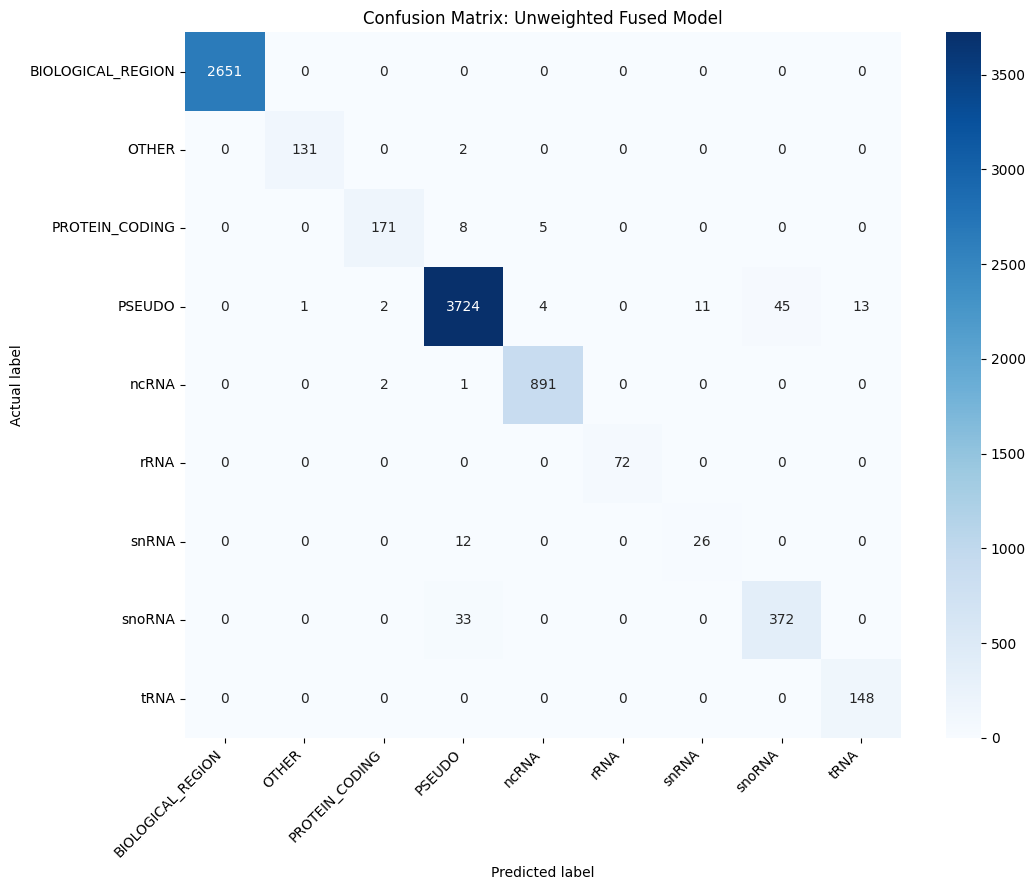

In [18]:

cm = confusion_matrix(
    y_test,
    pred_classes,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    cmap="Blues"
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix: Unweighted Fused Model")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [19]:

for cls, support, correct in zip(
    le.classes_,
    cm.sum(axis=1),
    np.diag(cm)
):
    print(
        f"{cls}: {support - correct} errors out of {support}"
    )

print("Total errors:", int(np.sum(pred_classes != y_test)))
print("Correct predictions:", int(np.sum(pred_classes == y_test)))


BIOLOGICAL_REGION: 0 errors out of 2651
OTHER: 2 errors out of 133
PROTEIN_CODING: 13 errors out of 184
PSEUDO: 76 errors out of 3800
ncRNA: 3 errors out of 894
rRNA: 0 errors out of 72
snRNA: 12 errors out of 38
snoRNA: 33 errors out of 405
tRNA: 0 errors out of 148
Total errors: 139
Correct predictions: 8186


In [20]:

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

seq_input_lstm = Input(shape=(MAX_LEN,), name="dna_input_lstm")

x_lstm = Embedding(
    input_dim=len(dna_tokenizer.word_index) + 1,
    output_dim=8
)(seq_input_lstm)

x_lstm = LSTM(64)(x_lstm)
x_lstm = Dropout(0.3)(x_lstm)

x_lstm = Dense(128, activation="relu")(x_lstm)
x_lstm = Dropout(0.3)(x_lstm)

output_lstm = Dense(
    num_classes,
    activation="softmax"
)(x_lstm)

model_lstm = Model(
    inputs=seq_input_lstm,
    outputs=output_lstm
)

model_lstm.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_lstm.summary()

history_lstm = model_lstm.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=50,
    batch_size=64,
    verbose=1
)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dna_input_lstm (InputLayer)     │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 500, 8)         │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,225 (110.25 KB)

 Trainable params: 28,225 (110.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 113s 307ms/step - accuracy: 0.4602 - loss: 1.4215 - val_accuracy: 0.4898 - val_loss: 1.3014
Epoch 2/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 147s 323ms/step - accuracy: 0.4647 - loss: 1.3621 - val_accuracy: 0.4660 - val_loss: 1.3067
Epoch 3/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 128s 362ms/step - accuracy: 0.4667 - loss: 1.3502 - val_accuracy: 0.4818 - val_loss: 1.3054
Epoch 4/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 123s 307ms/step - accuracy: 0.4659 - loss: 1.3506 - val_accuracy: 0.4660 - val_loss: 1.3096
Epoch 5/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 107s 303ms/step - accuracy: 0.4615 - loss: 1.3432 - val_accuracy: 0.4826 - val_loss: 1.2960
Epoch 6/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 106s 301ms/step - accuracy: 0.4819 - loss: 1.3311 - val_accuracy: 0.5250 - val_loss: 1.2667
Epoch 7/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 107s 303ms/step - accuracy: 0.5198 - loss: 1.2830 - val_accuracy: 0.4335 - val_loss: 1.2358
Epoch 8/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 107s 303ms/step - accuracy: 0.6324 -

In [21]:

pred_lstm = np.argmax(
    model_lstm.predict(X_test_seq, verbose=0),
    axis=1
)

lstm_accuracy = accuracy_score(y_test, pred_lstm)

print(f"LSTM-only accuracy: {lstm_accuracy:.6f}")
print(f"LSTM-only accuracy: {lstm_accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_lstm,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


LSTM-only accuracy: 0.753033
LSTM-only accuracy: 75.30%

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     0.9553    0.7657    0.8501      2651
            OTHER     0.5426    0.5263    0.5344       133
   PROTEIN_CODING     0.0000    0.0000    0.0000       184
           PSEUDO     0.7404    0.8903    0.8085      3800
            ncRNA     0.5939    0.4172    0.4901       894
             rRNA     0.5349    0.9583    0.6866        72
            snRNA     0.0000    0.0000    0.0000        38
           snoRNA     0.5954    0.5704    0.5826       405
             tRNA     0.3165    0.7635    0.4475       148

         accuracy                         0.7530      8325
        macro avg     0.4755    0.5435    0.4889      8325
     weighted avg     0.7538    0.7530    0.7431      8325



In [22]:

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

text_input_tfidf = Input(
    shape=(X_train_text.shape[1],),
    name="tfidf_input"
)

y_tfidf = Dense(256, activation="relu")(text_input_tfidf)
y_tfidf = Dropout(0.3)(y_tfidf)

y_tfidf = Dense(128, activation="relu")(y_tfidf)
y_tfidf = Dropout(0.3)(y_tfidf)

output_tfidf = Dense(
    num_classes,
    activation="softmax"
)(y_tfidf)

model_tfidf = Model(
    inputs=text_input_tfidf,
    outputs=output_tfidf
)

model_tfidf.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_tfidf.summary()

history_tfidf = model_tfidf.fit(
    X_train_text,
    y_train,
    validation_data=(X_val_text, y_val),
    epochs=50,
    batch_size=64,
    verbose=1
)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tfidf_input (InputLayer)        │ (None, 3000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       768,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 802,313 (3.06 MB)

 Trainable params: 802,313 (3.06 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9032 - loss: 0.3848 - val_accuracy: 0.9755 - val_loss: 0.0747
Epoch 2/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9717 - loss: 0.0830 - val_accuracy: 0.9803 - val_loss: 0.0553
Epoch 3/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9761 - loss: 0.0658 - val_accuracy: 0.9803 - val_loss: 0.0520
Epoch 4/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9768 - loss: 0.0608 - val_accuracy: 0.9801 - val_loss: 0.0510
Epoch 5/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9792 - loss: 0.0567 - val_accuracy: 0.9801 - val_loss: 0.0492
Epoch 6/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9791 - loss: 0.0549 - val_accuracy: 0.9799 - val_loss: 0.0484
Epoch 7/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9792 - loss: 0.0527 - val_accuracy: 0.9806 - val_loss: 0.0482
Epoch 8/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9797 - loss: 0.0514 - val_acc

In [23]:

pred_tfidf = np.argmax(
    model_tfidf.predict(X_test_text, verbose=0),
    axis=1
)

tfidf_accuracy = accuracy_score(y_test, pred_tfidf)

print(f"TF-IDF-only accuracy: {tfidf_accuracy:.6f}")
print(f"TF-IDF-only accuracy: {tfidf_accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_tfidf,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


TF-IDF-only accuracy: 0.980661
TF-IDF-only accuracy: 98.07%

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     1.0000    1.0000    1.0000      2651
            OTHER     0.9924    0.9850    0.9887       133
   PROTEIN_CODING     0.9581    0.8696    0.9117       184
           PSEUDO     0.9846    0.9763    0.9804      3800
            ncRNA     0.9717    0.9989    0.9851       894
             rRNA     1.0000    1.0000    1.0000        72
            snRNA     0.7027    0.6842    0.6933        38
           snoRNA     0.8923    0.9210    0.9064       405
             tRNA     0.9193    1.0000    0.9579       148

         accuracy                         0.9807      8325
        macro avg     0.9357    0.9372    0.9360      8325
     weighted avg     0.9809    0.9807    0.9806      8325



In [24]:

logreg = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)

logreg.fit(X_train_text, y_train)

pred_lr = logreg.predict(X_test_text)

accuracy_lr = accuracy_score(y_test, pred_lr)
weighted_f1_lr = f1_score(
    y_test, pred_lr, average="weighted"
)
macro_f1_lr = f1_score(
    y_test, pred_lr, average="macro"
)

print(f"Logistic Regression accuracy: {accuracy_lr:.6f}")
print(f"Logistic Regression accuracy: {accuracy_lr * 100:.2f}%")
print(f"Weighted F1: {weighted_f1_lr:.4f}")
print(f"Macro F1: {macro_f1_lr:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_lr,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


Logistic Regression accuracy: 0.975495
Logistic Regression accuracy: 97.55%
Weighted F1: 0.9753
Macro F1: 0.9186

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     0.9996    1.0000    0.9998      2651
            OTHER     0.9429    0.9925    0.9670       133
   PROTEIN_CODING     0.9433    0.7228    0.8185       184
           PSEUDO     0.9795    0.9697    0.9746      3800
            ncRNA     0.9758    0.9933    0.9845       894
             rRNA     1.0000    1.0000    1.0000        72
            snRNA     0.7027    0.6842    0.6933        38
           snoRNA     0.8824    0.9630    0.9209       405
             tRNA     0.8521    0.9730    0.9085       148

         accuracy                         0.9755      8325
        macro avg     0.9198    0.9221    0.9186      8325
     weighted avg     0.9761    0.9755    0.9753      8325



In [25]:

leak_terms = [
    "pseudogene", "regulatory region", "cis-regulatory", "enhancer",
    "small nucleolar", "small nuclear", "spliceosomal", "ribosomal",
    "microrna", "uncharacterized", "trna", "immunoglobulin",
    "t cell receptor", "histone", "olfactory receptor", "mpra"
]

def strip_leakage(text):
    cleaned = str(text).lower()

    for term in leak_terms:
        cleaned = cleaned.replace(term, "")

    return cleaned


train_descriptions_clean = train_df["Description"].apply(strip_leakage)
val_descriptions_clean = val_df["Description"].apply(strip_leakage)
test_descriptions_clean = test_df["Description"].apply(strip_leakage)

tfidf_clean = TfidfVectorizer(max_features=3000)

X_train_text_clean = tfidf_clean.fit_transform(
    train_descriptions_clean
).toarray()

X_val_text_clean = tfidf_clean.transform(
    val_descriptions_clean
).toarray()

X_test_text_clean = tfidf_clean.transform(
    test_descriptions_clean
).toarray()

logreg_clean = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)

logreg_clean.fit(X_train_text_clean, y_train)

pred_lr_clean = logreg_clean.predict(X_test_text_clean)

accuracy_lr_clean = accuracy_score(y_test, pred_lr_clean)
weighted_f1_lr_clean = f1_score(
    y_test, pred_lr_clean, average="weighted"
)
macro_f1_lr_clean = f1_score(
    y_test, pred_lr_clean, average="macro"
)

print(f"Leakage-stripped Logistic Regression accuracy: {accuracy_lr_clean:.6f}")
print(f"Leakage-stripped accuracy: {accuracy_lr_clean * 100:.2f}%")
print(f"Weighted F1: {weighted_f1_lr_clean:.4f}")
print(f"Macro F1: {macro_f1_lr_clean:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_lr_clean,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


Leakage-stripped Logistic Regression accuracy: 0.940180
Leakage-stripped accuracy: 94.02%
Weighted F1: 0.9357
Macro F1: 0.7934

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     0.9985    0.9977    0.9981      2651
            OTHER     0.8058    0.8421    0.8235       133
   PROTEIN_CODING     0.7536    0.2826    0.4111       184
           PSEUDO     0.9435    0.9313    0.9374      3800
            ncRNA     0.8496    0.9922    0.9154       894
             rRNA     0.9114    1.0000    0.9536        72
            snRNA     0.8750    0.1842    0.3043        38
           snoRNA     0.8842    0.9235    0.9034       405
             tRNA     0.8528    0.9392    0.8939       148

         accuracy                         0.9402      8325
        macro avg     0.8749    0.7881    0.7934      8325
     weighted avg     0.9394    0.9402    0.9357      8325



In [26]:

results_summary = pd.DataFrame({
    "Model": [
        "Fused LSTM + TF-IDF (unweighted)",
        "LSTM-only (unweighted)",
        "Neural TF-IDF-only",
        "Logistic Regression (original text)",
        "Logistic Regression (leakage-stripped)"
    ],
    "Accuracy (%)": [
        fused_accuracy * 100,
        lstm_accuracy * 100,
        tfidf_accuracy * 100,
        accuracy_lr * 100,
        accuracy_lr_clean * 100
    ],
    "Weighted F1": [
        f1_score(y_test, pred_classes, average="weighted"),
        f1_score(y_test, pred_lstm, average="weighted"),
        f1_score(y_test, pred_tfidf, average="weighted"),
        weighted_f1_lr,
        weighted_f1_lr_clean
    ],
    "Macro F1": [
        f1_score(y_test, pred_classes, average="macro"),
        f1_score(y_test, pred_lstm, average="macro"),
        f1_score(y_test, pred_tfidf, average="macro"),
        macro_f1_lr,
        macro_f1_lr_clean
    ]
})

print(results_summary.to_string(index=False))


                                 Model  Accuracy (%)  Weighted F1  Macro F1
      Fused LSTM + TF-IDF (unweighted)     98.330330     0.983341  0.941510
                LSTM-only (unweighted)     75.303303     0.743135  0.488859
                    Neural TF-IDF-only     98.066066     0.980642  0.935957
   Logistic Regression (original text)     97.549550     0.975270  0.918571
Logistic Regression (leakage-stripped)     94.018018     0.935720  0.793412
